# 4. Feature Selection — Ridge & Lasso
**APRAU 2026/27 — Group 18**

Compare classification performance using:
- All features (baseline)
- Features selected via **Ridge** (L2) regularization
- Features selected via **Lasso** (L1) regularization

## 1. Setup

In [12]:
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18_cleaned.csv'
else:
    DATASET_PATH = '../dataset_grupo_18_cleaned.csv'

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, RidgeClassifier, Lasso
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectFromModel

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Data Loading & Preprocessing

In [14]:
df = pd.read_csv(DATASET_PATH)

df_enc = df.copy()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

TARGET = 'target_class'
FEATURES = [c for c in df_enc.columns if c not in [TARGET, 'target_regression']]

X = df_enc[FEATURES].values
y = df_enc[TARGET].values
feature_names = np.array(FEATURES)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Total features: {len(FEATURES)}')

Total features: 30


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_features(X_subset, label):
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    scores = cross_val_score(clf, X_subset, y, cv=cv, scoring='accuracy')
    print(f'{label}: {np.mean(scores):.4f} ± {np.std(scores):.4f}  (n_features={X_subset.shape[1]})')
    return {'Feature Set': label, 'n_features': X_subset.shape[1],
            'Mean Accuracy': np.mean(scores), 'Std': np.std(scores)}

## 3. Baseline — All Features

In [16]:
comparison = []
comparison.append(evaluate_features(X_scaled, 'All Features'))

All Features: 0.9015 ± 0.0094  (n_features=30)


## 4. Ridge (L2) — Feature Importance

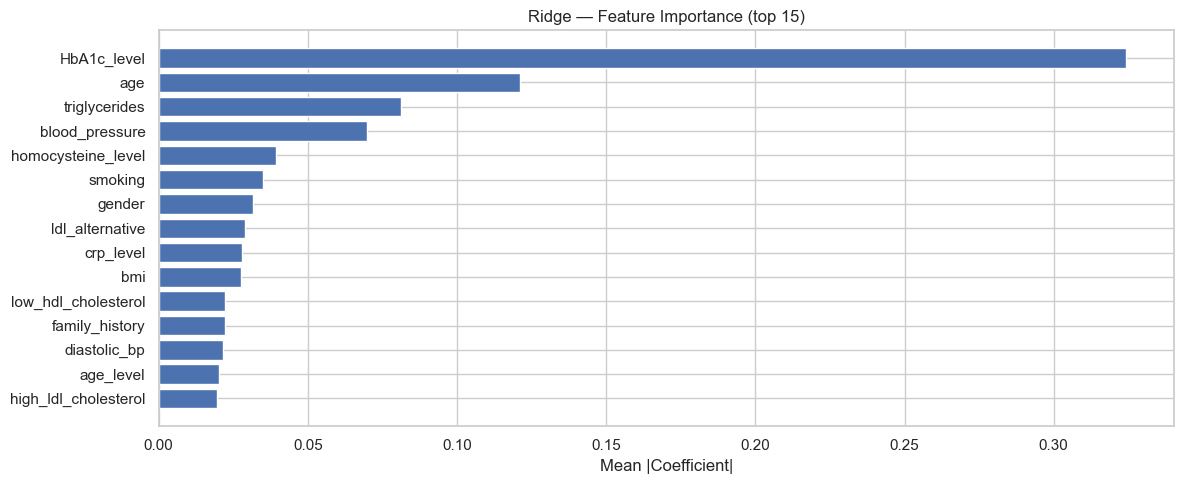

In [17]:
# Ridge classifier coefficients show feature importance
ridge = RidgeClassifier(alpha=1.0)
ridge.fit(X_scaled, y)

ridge_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(ridge.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

plt.barh(ridge_importance['Feature'][:15][::-1], ridge_importance['Coefficient'][:15][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Ridge — Feature Importance (top 15)')
plt.tight_layout()
plt.show()

In [18]:
# Select top N features by Ridge importance
TOP_N = 10
ridge_top_feats = ridge_importance.head(TOP_N)['Feature'].tolist()
feat_idx = [list(feature_names).index(f) for f in ridge_top_feats]
X_ridge = X_scaled[:, feat_idx]

comparison.append(evaluate_features(X_ridge, f'Ridge Top {TOP_N}'))

Ridge Top 10: 0.9065 ± 0.0080  (n_features=10)


## 5. Lasso (L1) — Feature Selection

Lasso selected 22 features: ['HbA1c_level', 'age', 'triglycerides', 'blood_pressure', 'smoking', 'gender', 'homocysteine_level', 'family_history', 'low_hdl_cholesterol', 'ldl_alternative', 'crp_level', 'sugar_consumption', 'education_level', 'bmi', 'high_ldl_cholesterol', 'diastolic_bp', 'plasma_value', 'age_level', 'systolic_bp', 'physical_activity', 'cholesterol', 'sleep_hours']


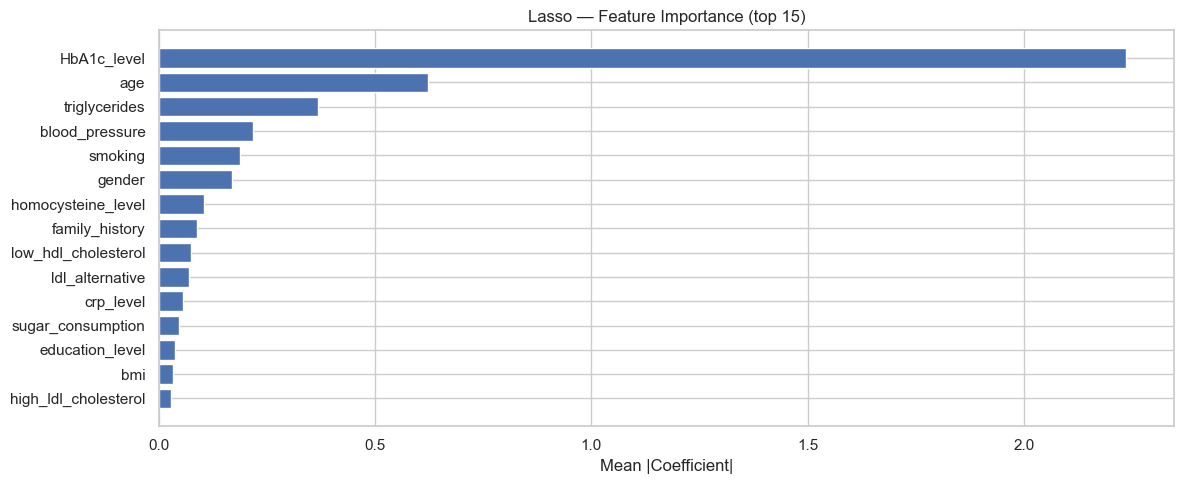

In [19]:
# Lasso with LogisticRegression (penalty='l1') zeroes out irrelevant features
lasso_clf = LogisticRegression(
    penalty='l1', solver='liblinear', C=0.1,
    max_iter=1000, random_state=RANDOM_STATE
)
lasso_clf.fit(X_scaled, y)

lasso_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(lasso_clf.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

lasso_selected = lasso_importance[lasso_importance['Coefficient'] > 0]['Feature'].tolist()
print(f'Lasso selected {len(lasso_selected)} features: {lasso_selected}')

plt.barh(lasso_importance['Feature'][:15][::-1], lasso_importance['Coefficient'][:15][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Lasso — Feature Importance (top 15)')
plt.tight_layout()
plt.show()

In [20]:
if len(lasso_selected) > 0:
    feat_idx_lasso = [list(feature_names).index(f) for f in lasso_selected]
    X_lasso = X_scaled[:, feat_idx_lasso]
    comparison.append(evaluate_features(X_lasso, f'Lasso Selected ({len(lasso_selected)})'))
else:
    print('Lasso eliminated all features — try increasing C (weaker regularization)')

Lasso Selected (22): 0.9040 ± 0.0073  (n_features=22)


## 6. Comparison

In [21]:
comp_df = pd.DataFrame(comparison)
comp_df

,Feature Set,n_features,Mean Accuracy,Std
0,All Features,30,0.9015,0.009434
1,Ridge Top 10,10,0.9065,0.008000
2,Lasso Selected (22),22,0.9040,0.007348


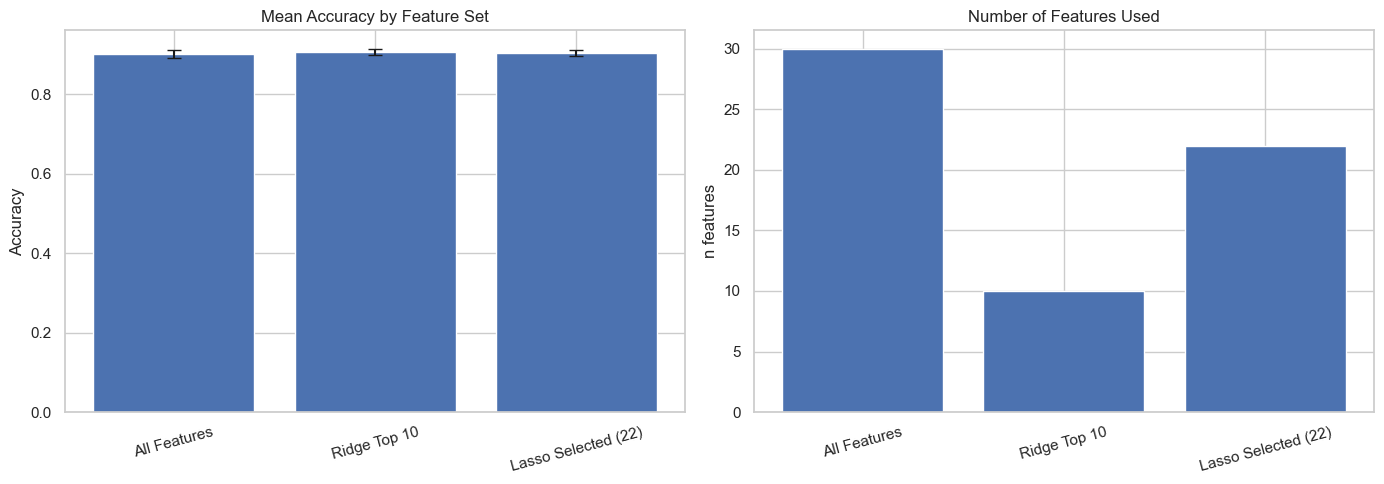

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(comp_df['Feature Set'], comp_df['Mean Accuracy'], yerr=comp_df['Std'], capsize=5)
axes[0].set_title('Mean Accuracy by Feature Set')
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(comp_df['Feature Set'], comp_df['n_features'])
axes[1].set_title('Number of Features Used')
axes[1].set_ylabel('n features')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## Discussion

*(Fill in after running the models)*

- **Features removed by Lasso:**
- **Performance impact of reducing features:**
- **Ridge vs Lasso — key differences observed:**
- **Recommended feature set and justification:**